# Cued-response model — single population, matrix cue

The `binding_capacity` model: a fixed retinotopic/relational population that says *where* two
objects are but not *which is which*, plus a deliberately low-capacity **cue** channel that
carries the ordering, and a readout that must fuse the two to report the **first** object's
location.

There is **no titration** and **no gain fitting**: you specify the population (number of
retinotopic and relational neurons) and its gain (`baseline = amplitude = GAIN`) directly,
and one cued-response model is fit on it.

The notebook makes one figure, **$W$ by unit**: the total cue→state weight each population
neuron receives, which is where the model says it spent its fixed synaptic budget. $W$ is
learned, so the model is trained first.

## How the model works (`task_lib.CueMatrixModel`)

The population is fixed (never trained), with 2-object rate `neural = GAIN ·
shape` (baseline = amplitude = GAIN). The trainable cue-response model is:

```
cue feats ─► cue MLP ─► sigmoid·CUE_MAX_RATE ─► Poisson ─► cue_sample   (dim CUE_OUTPUT_NEURONS)
                                                              │
                                       W ≥ 0  (mean entry = CUE_INFLUENCE)
                                                              │
neural rate ───────────────────(+)◄──── delta = W · cue_sample
                                 │
                             ReLU ─► Poisson ─► readout MLP ─► output bump (N_ANGLES)
```

- **Cue channel.** The ordered features $[\cos\theta_0,\sin\theta_0,\cos\theta_1,
  \sin\theta_1]$ go through the cue MLP and a sigmoid scaled by `CUE_MAX_RATE`,
  giving a latent **rate** in $(0,\text{CUE\_MAX\_RATE})$ for each of
  `CUE_OUTPUT_NEURONS` cue units. That rate is **Poisson-sampled** — so the cue
  is a real, discrete, noisy spike channel whose capacity is set by
  `CUE_MAX_RATE` (spikes per unit) and `CUE_OUTPUT_NEURONS` (how many units).
- **Non-negative projection with a fixed budget.** A weight matrix
  $W\in\mathbb{R}^{n_\text{neurons}\times\text{CUE\_OUTPUT\_NEURONS}}$ maps the
  cue spikes to a **delta** added to the population state,
  $\text{delta}=W\,\text{cue\_sample}$. $W$ is always **entrywise non-negative**,
  and its entries **average** `CUE_INFLUENCE` (a fixed cue→population synaptic budget).

  This is enforced exactly (not by penalty) from a softmax base
  $p=\mathrm{softmax}(W_\text{logits})$ (entrywise positive, summing to 1):
  $W=\text{CUE\_INFLUENCE}\cdot N\,p$, with $N$ the number of entries. Training
  decides how to *distribute* the weights, but their mean is held fixed.
- **Population readout.** The delta is added to the state, rectified, and the sum
  is **Poisson-sampled once** (the population's own trial noise), then a readout MLP produces the bump at
  the first object $\theta_0$. Loss is MSE against a circular-Gaussian target.

Both Poisson draws use a straight-through estimator (sample forward, pass the
rate's gradient backward), so the cue MLP, $W$, and the readout all train.
Only these three components are trainable — the population and its gain are
fixed inputs you set.

In [1]:
# ── CONFIG ──────────────────────────────
# Population (specified directly — no titration, no gain fitting) --------------
NUM_RETINOTOPIC = 64     # retinotopic neurons (2-object response = sum of both objects)
NUM_RELATIONAL  = 64     # relational neurons (tuned to the segment angle between objects)
GAIN            = 0.5   # baseline = amplitude = GAIN for every neuron (you set this)

# Task ------------------------------------------------------------------------
MIN_SEP_DEG      = 90.0   # minimum object–object separation
N_ANGLES         = 96     # decode-grid resolution (output/target length)
TARGET_SIGMA_DEG = 12.0   # width of the target bump centered on θ₀

# Cue-response model ----------------------------------------------------------
CUE_HIDDEN         = [64, 64]     # cue MLP hidden sizes
READOUT_HIDDEN     = [128, 128]   # readout MLP hidden sizes
CUE_OUTPUT_NEURONS = 4           # dimensionality of the Poisson-sampled cue representation
CUE_MAX_RATE       = 1.0          # max Poisson rate per cue unit (sigmoid scale)
CUE_INFLUENCE      = 0.2          # mean of the (non-negative) cue->state weights

# Training --------------------------------------------------------------------
BATCH_SIZE = 256
N_STEPS    = 3000
LR         = 2e-3

# Figure: W by unit -----------------------------------------------------------
W_LINE_FIGSIZE  = (3.3, 2.7)   # inches — sized so 12 pt labels fit
W_LINE_DPI      = 300
W_LINE_FONTSIZE = 12           # FORMATTING.md: no font below 12 pt, anywhere
W_BLOCK_FONTSIZE = 14          # the 'Retinotopic' / 'Relational' labels inside the panel
OUTPUT_PDF_W    = 'w_by_unit.pdf'

SEED = 0
# ────────────────────────────────────

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch

import task_lib as tl        # the task and the CueMatrixModel

import sys
from pathlib import Path

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.append(str(paths.FIGURES / 'supp_figure_7'))
import common

common.set_style()

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

cfg = dict(n_angles=N_ANGLES, min_sep_deg=MIN_SEP_DEG, target_sigma_deg=TARGET_SIGMA_DEG,
           batch_size=BATCH_SIZE, n_steps=N_STEPS, lr=LR)

## Build the population and the model

In [3]:
pop = tl.make_population(NUM_RETINOTOPIC, NUM_RELATIONAL, GAIN, GAIN)
model = tl.CueMatrixModel(
    n_neurons=tl.n_neurons(pop), n_angles=N_ANGLES,
    cue_hidden=CUE_HIDDEN, readout_hidden=READOUT_HIDDEN,
    cue_output_neurons=CUE_OUTPUT_NEURONS, cue_max_rate=CUE_MAX_RATE,
    cue_influence=CUE_INFLUENCE)

n_params = sum(p.numel() for p in model.parameters())
print(f'{tl.n_neurons(pop)} neurons '
      f'({pop["n_retinotopic"]} retinotopic + {pop["n_relational"]} relational), '
      f'baseline = amplitude = {GAIN:g} Hz')
with torch.no_grad():
    W0 = model.cue_weight_matrix()
print(f'cue matrix W: {tuple(W0.shape)}  (>=0: {bool((W0 >= 0).all())}, '
      f'mean = {float(W0.mean()):.3f} = CUE_INFLUENCE [mean_weight])')
print(f'model: {n_params} trainable parameters')

128 neurons (64 retinotopic + 64 relational), baseline = amplitude = 0.5 Hz
cue matrix W: (128, 4)  (>=0: True, mean = 0.200 = CUE_INFLUENCE [mean_weight])
model: 50660 trainable parameters


## Train

Adam on MSE between the model output bump and the target bump centered on $\theta_0$. Every
batch draws fresh stimuli, a fresh cue Poisson sample, and a fresh population Poisson sample,
so the model trains against the full noise. The loss is printed as it goes; it is not
plotted.

In [4]:
losses, grid = tl.train_model(model, pop, cfg, rng, log_every=max(1, N_STEPS // 10))

step     0/3000  MSE=0.0830
step   300/3000  MSE=0.0266
step   600/3000  MSE=0.0226
step   900/3000  MSE=0.0214
step  1200/3000  MSE=0.0215
step  1500/3000  MSE=0.0214
step  1800/3000  MSE=0.0225
step  2100/3000  MSE=0.0228
step  2400/3000  MSE=0.0202
step  2700/3000  MSE=0.0206
step  2999/3000  MSE=0.0216


## $W$ by unit

The learned cue→state matrix $W$ (non-negative, its mean fixed at `CUE_INFLUENCE`) summed across cue units: the **total cue drive each population neuron
receives**. The retinotopic block is on the left of the dotted divider and the relational
block on the right, so the x axis follows the population's own ordering.

Training decides how to *distribute* the budget, not how large it is — so where the line sits
is the model's answer to which neurons the ordering information is worth injecting into.

saved w_by_unit.pdf


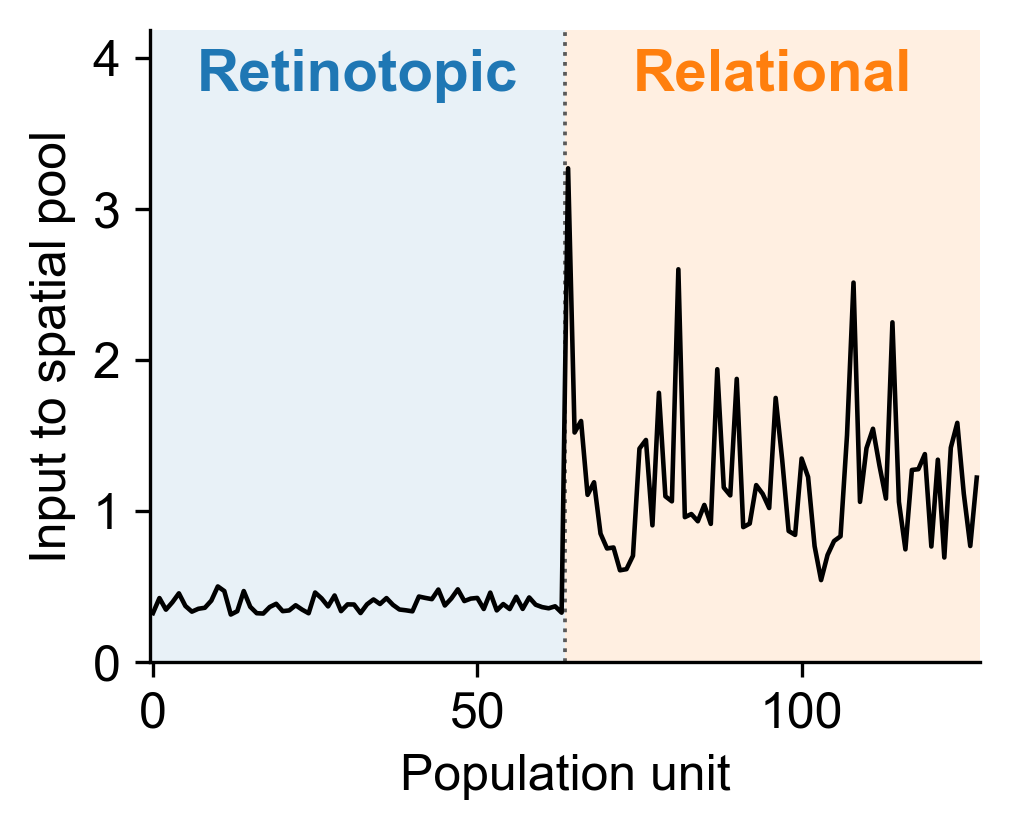

mean weight: retinotopic 0.0965, relational 0.3035


In [5]:
# The same W as a lineplot over population units: the TOTAL cue drive into each
# neuron (the row sum). Retinotopic units on the left, relational on the right, with
# the two regions shaded and labelled.
with torch.no_grad():
    W = model.cue_weight_matrix().cpu().numpy()
x = np.arange(W.shape[0])
w_sum = W.sum(axis=1)

with plt.rc_context({'font.size': W_LINE_FONTSIZE, 'axes.titlesize': W_LINE_FONTSIZE,
                     'axes.labelsize': W_LINE_FONTSIZE,
                     'xtick.labelsize': W_LINE_FONTSIZE,
                     'ytick.labelsize': W_LINE_FONTSIZE,
                     'legend.fontsize': W_LINE_FONTSIZE, 'lines.linewidth': 1.0}):
    fig, ax = plt.subplots(figsize=W_LINE_FIGSIZE, dpi=W_LINE_DPI)
    # shade + label the two blocks
    ax.axvspan(-0.5, NUM_RETINOTOPIC - 0.5, color='tab:blue', alpha=0.10, lw=0)
    ax.axvspan(NUM_RETINOTOPIC - 0.5, W.shape[0] - 0.5, color='tab:orange', alpha=0.12, lw=0)
    ax.axvline(NUM_RETINOTOPIC - 0.5, color='0.35', ls=':', lw=0.9)
    ax.plot(x, w_sum, color='k', lw=1.1)
    ax.set_xlim(-0.5, W.shape[0] - 0.5)
    ax.set_ylim(0, w_sum.max() * 1.28)
    for x0, x1, lab, col in [(-0.5, NUM_RETINOTOPIC - 0.5, 'Retinotopic', 'tab:blue'),
                             (NUM_RETINOTOPIC - 0.5, W.shape[0] - 0.5, 'Relational', 'tab:orange')]:
        ax.text(0.5 * (x0 + x1), 0.97, lab, transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=W_BLOCK_FONTSIZE, color=col, weight='bold')
    ax.set_xlabel('Population unit')
    ax.set_ylabel('Input to spatial pool')
    common.despine(ax)                       # FORMATTING.md: despine every data plot
    fig.tight_layout(pad=0.4)
    common.save(fig, OUTPUT_PDF_W)
    plt.show()
print(f'mean weight: retinotopic {W[:NUM_RETINOTOPIC].mean():.4f}, '
      f'relational {W[NUM_RETINOTOPIC:].mean():.4f}')